# Ground-state methods for the 1D TFIM: what each does, what it costs, how they compare

$H = -\sum_i \sigma^z_i\sigma^z_{i+1} - h\sum_i \sigma^x_i$, periodic, $J=1$; critical point $h=1$.
Every method below produces a variational energy **and** ground-state configurations (samples); the
free-fermion solution gives the exact $E_0$ and is used only as the reference.

| method | what it optimises | knob that controls accuracy | samples | cost grows with |
|---|---|---|---|---|
| **product state** (mean field) | one spin angle, analytic | none (no entanglement) | exact, i.i.d. | — |
| **DMRG / MPS** | matrix product state | bond dimension χ (χ = 1 = product state) | exact, i.i.d. (sequential) | N χ³ per sweep |
| **RBM + exact SR** | RBM, $M=N$ hidden units, exact gradients over all $2^N$ states | ansatz only (no noise) | — (ceiling, $N\le16$) | $2^N$ |
| **RBM + SR, exact samples** | same, 200 i.i.d. samples per step | + Monte Carlo noise | exact, i.i.d. | $2^N$ (sampling by enumeration) |
| **RBM + SR, persistent Gibbs** | same, 200 Gibbs chains × 10 sweeps per step | + MCMC bias / autocorrelation | Markov chain | N M per sweep, × steps |

The three RBM rows are one ansatz with three ways of estimating the gradient, so their differences isolate the
**impact of each ingredient**: exact SR = error of the ansatz itself; exact samples − exact SR = cost of
Monte Carlo noise; Gibbs − exact samples = cost of using a Markov chain instead of perfect samples.

Data: RBM runs `results/mf_vs_h/` (`scripts/exper/mf_vs_h.py`; SR lr 0.08, reg 0.05; final energies by
enumeration for $N\le16$, global-flip Metropolis otherwise), DMRG `results/dmrg_baseline/tfim1d.jsonl`
(`scripts/validation/dmrg_baseline.py`), product state `src/mean_field.py`. Re-run all cells after new runs land.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src" / "mean_field.py").exists()), None)
assert REPO is not None, "run this notebook from inside the adiabatic-boltzmann repository"
sys.path.insert(0, str(REPO / "src"))
import jax; jax.config.update("jax_enable_x64", True)
from ising import TransverseFieldIsing1D
from mean_field import mean_field_energy, mean_field_angle

DATA = REPO / "results" / "mf_vs_h"
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"exact_sr": "#008300", "exact": "#2a78d6", "gibbs": "#e87ba4", "gibbs_mfinit": "#7b3fbf", "gibbs_a2": "#d97a00"}
MARKERS = {"exact_sr": "s", "exact": "o", "gibbs": "^", "gibbs_mfinit": "v", "gibbs_a2": "D"}
LABELS = {"exact_sr": "exact SR (ansatz ceiling)", "exact": "SR, exact samples", "gibbs": "SR, persistent Gibbs",
          "gibbs_mfinit": "Gibbs, product-state start", "gibbs_a2": "Gibbs, M = 2N"}

## 1. The methods
### 1.1 Product state (mean field, χ = 1)
Best uniform product state, $\sin\alpha = h/2$ for $h\le 2$, $E_{MF}/N = -(1+h^2/4)$; x-polarised ($-h$) above.
No correlations at all, so its error measures how entangled the ground state is: tiny deep in either phase,
largest around (and, because mean field puts the transition at $h=2$, above) the critical point.

In [2]:
def e0_inf(h):
    """Thermodynamic-limit ground energy per spin (free fermions)."""
    k = np.linspace(0, np.pi, 200001)
    return -np.trapezoid(np.sqrt(1 + h * h - 2 * h * np.cos(k)), k) / np.pi

def mf_err(N, h):
    """Product-state error per spin, (E_MF - E0)/N."""
    m = TransverseFieldIsing1D(N, h)
    return (mean_field_energy(m) - m.exact_ground_energy()) / N

def e0_per_spin(N, h):
    return abs(TransverseFieldIsing1D(N, h).exact_ground_energy()) / N

def mf_rel(N, h):
    """Product-state relative error, (E_MF - E0)/|E0| (fraction, not %)."""
    return mf_err(N, h) / e0_per_spin(N, h)

rows = []
for h in (0.25, 0.5, 0.8, 0.9, 0.95, 1.0, 1.05, 1.1, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0):
    emf = -(1 + h * h / 4) if h <= 2 else -h
    rows.append(dict(h=h, E0_inf=e0_inf(h), E_MF=emf, sz_MF=np.cos(mean_field_angle(TransverseFieldIsing1D(8, h))),
                     err_N8=mf_err(8, h), err_N16=mf_err(16, h), err_N64=mf_err(64, h), err_inf=emf - e0_inf(h),
                     rel_pct_N8=100 * mf_rel(8, h), rel_pct_N16=100 * mf_rel(16, h), rel_pct_N64=100 * mf_rel(64, h),
                     rel_pct_inf=100 * (emf - e0_inf(h)) / abs(e0_inf(h))))
mf_table = pd.DataFrame(rows).set_index("h")
mf_table  # err_*: error per spin (E_MF - E0)/N;  rel_pct_*: relative error (E_MF - E0)/|E0| in %

,E0_inf,E_MF,sz_MF,err_N8,err_N16,err_N64,err_inf,rel_pct_N8,rel_pct_N16,rel_pct_N64,rel_pct_inf
h,,,,,,,,,,,
0.25,-1.016,-1.016,9.922e-01,6.240e-05,6.201e-05,6.201e-05,6.201e-05,0.006,0.006,0.006,0.006
0.50,-1.064,-1.062,9.682e-01,1.135e-03,1.045e-03,1.044e-03,1.044e-03,0.107,0.098,0.098,0.098
0.80,-1.168,-1.160,9.165e-01,1.065e-02,7.972e-03,7.810e-03,7.810e-03,0.910,0.683,0.669,0.669
0.90,-1.216,-1.203,8.930e-01,1.916e-02,1.431e-02,1.350e-02,1.350e-02,1.568,1.176,1.110,1.110
0.95,-1.243,-1.226,8.800e-01,2.485e-02,1.911e-02,1.765e-02,1.764e-02,1.987,1.535,1.420,1.419
1.00,-1.273,-1.250,8.660e-01,3.146e-02,2.529e-02,2.337e-02,2.324e-02,2.455,1.983,1.835,1.825
1.05,-1.307,-1.276,8.511e-01,3.887e-02,3.281e-02,3.125e-02,3.123e-02,2.957,2.507,2.391,2.390
1.10,-1.343,-1.302,8.352e-01,4.691e-02,4.136e-02,4.037e-02,4.036e-02,3.476,3.078,3.006,3.006
1.25,-1.460,-1.391,7.806e-01,7.269e-02,6.934e-02,6.914e-02,6.914e-02,4.967,4.749,4.736,4.736


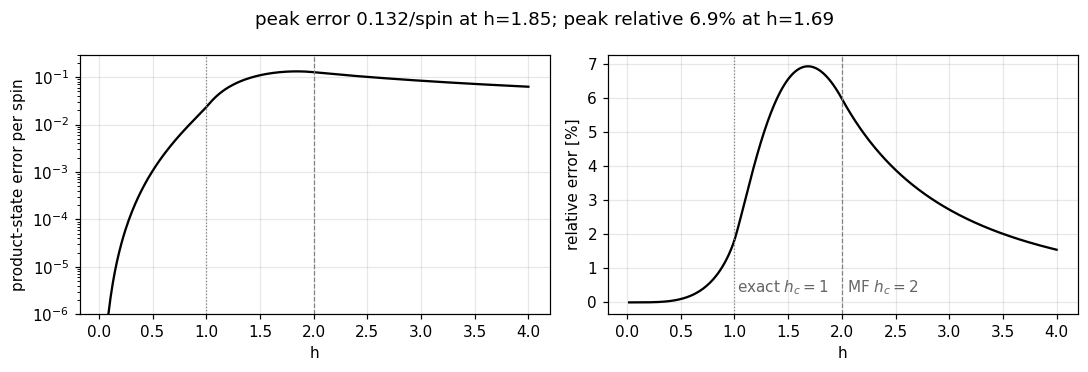

In [3]:
hh = np.linspace(0.02, 4, 400)
err = np.array([(-(1 + h * h / 4) if h <= 2 else -h) - e0_inf(h) for h in hh])
rel = err / np.abs([e0_inf(h) for h in hh])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(hh, err, "k"); ax[0].set_ylabel("product-state error per spin"); ax[0].set_yscale("log"); ax[0].set_ylim(1e-6, 0.3)
ax[1].plot(hh, 100 * rel, "k"); ax[1].set_ylabel("relative error [%]")
for a in ax:
    a.axvline(1, color="0.5", lw=0.8, ls=":"); a.axvline(2, color="0.5", lw=0.8, ls="--"); a.set_xlabel("h")
ax[1].text(1.02, 0.3, "exact $h_c=1$", color="0.4"); ax[1].text(2.05, 0.3, "MF $h_c=2$", color="0.4")
fig.suptitle(f"peak error {err.max():.3f}/spin at h={hh[err.argmax()]:.2f}; peak relative {100*rel.max():.1f}% at h={hh[rel.argmax()]:.2f}")
fig.tight_layout()

### 1.2 DMRG (matrix product state, bond dimension χ)
Two-site DMRG (TeNPy) on the periodic chain, best of three starts (all up, all +x, previous χ's state — small χ
otherwise lands in start-dependent local minima); energy = ⟨H⟩ of the returned MPS. Each state yields exact i.i.d.
σᶻ samples by sequential conditional sampling (with a random global spin flip, since DMRG breaks the Z2 symmetry in
the ordered phase). In 1D the ground-state entanglement is bounded (it grows only as log N at $h=1$), so a modest χ
suffices; the error falls fastest with χ away from $h=1$.

Errors near 1e-14 per spin are the double-precision floor (relative error ~1e-14 of E0, i.e. round-off), shaded grey:
read them as "exact to all stored digits", not as a measured accuracy. Wall time = all three starts, single thread,
pure-Python TeNPy on a shared loaded machine (±2×).

In [4]:
dm = pd.DataFrame(map(json.loads, (REPO / "results" / "dmrg_baseline" / "tfim1d.jsonl").read_text().splitlines()))
dm = dm.drop_duplicates(["N", "h", "chi"], keep="last").sort_values(["N", "h", "chi"])  # last written wins
FLOOR = 1e-13  # per spin: round-off level for |E0|/N ~ 1-2 (relative ~1e-14)
dm["err_plot"] = dm.err.clip(lower=1e-15)  # round-off can make err ~ -1e-14; keep it on the log axis
CHI_CMAP = plt.get_cmap("Blues")
CHIS = sorted(dm.chi.unique())
chi_color = {c: CHI_CMAP(0.35 + 0.65 * i / max(len(CHIS) - 1, 1)) for i, c in enumerate(CHIS)}

def shade_floor(a):
    a.axhspan(1e-16, FLOOR, color="0.9", lw=0, zorder=0)

def vmc_at(arm, step):
    """Median error over the seeds that reached `step`, with their count, per (N, h)."""
    d = df[(df.arm == arm) & (df.step == step)].dropna(subset=["err"])
    return d.groupby(["N", "h"]).agg(err=("err", "median"), n=("err", "size"), wall_s=("wall_s", "median"))

print(len(dm), "DMRG points;", dm.groupby("N").size().to_dict(), "; winning start:", dm.start.value_counts().to_dict())
dm.pivot_table(index=["N", "h"], columns="chi", values="err")  # error per spin (E - E0)/N

120 DMRG points; {16: 30, 32: 30, 64: 30, 128: 30} ; winning start: {'x': 47, 'up': 42, 'warm': 31}


chi             2          4          8          16         32
N   h                                                         
16  0.5  7.287e-05  3.743e-07  1.206e-07  8.407e-11  1.577e-14
    0.9  2.274e-03  9.030e-04  3.411e-05  4.276e-08  1.970e-11
    1.0  5.641e-03  1.509e-03  5.487e-05  8.237e-08  2.144e-11
    1.1  1.031e-02  9.970e-04  5.024e-05  7.057e-08  1.444e-11
    1.5  1.166e-02  1.352e-04  4.538e-06  4.065e-09  5.351e-13
    2.0  8.253e-03  2.699e-05  5.774e-07  1.840e-10  8.882e-16
32  0.5  3.655e-05  2.969e-07  2.663e-10  7.758e-13  6.373e-13
    0.9  8.486e-04  1.569e-04  5.391e-05  8.258e-07  4.504e-09
    1.0  2.675e-03  1.125e-03  1.960e-04  2.607e-06  1.184e-08
    1.1  5.969e-03  1.207e-03  1.058e-04  1.159e-06  4.568e-09
    1.5  5.919e-03  1.619e-04  6.228e-06  1.237e-08  7.220e-12
    2.0  4.145e-03  3.240e-05  7.313e-07  4.715e-10  2.531e-14
64  0.5  1.844e-05  3.188e-07  2.993e-10  1.659e-13 -1.998e-15
    0.9  4.623e-04  1.932e-04  3.710e-06  6.481e-07  2.754e-08
    1.0  1.569e-03  1.017e-03  2.103e-04  1.496e-05  2.542e-07
    1.1  3.810e-03  1.337e-03  5.750e-05  2.083e-06  2.535e-08
    1.5  3.056e-03  1.779e-04  4.476e-06  8.069e-09  9.426e-12
    2.0  2.092e-03  3.516e-05  5.701e-07  5.380e-10  3.286e-14
128 0.5  9.392e-06  3.297e-07  3.122e-10  1.694e-13 -2.154e-14
    0.9  2.937e-04  1.420e-04  2.010e-06  3.429e-08  3.664e-10
    1.0  1.112e-03  5.311e-04  9.618e-05  3.515e-05  1.551e-06
    1.1  2.668e-03  1.355e-03  3.686e-05  2.210e-06  3.623e-08
    1.5  1.625e-03  1.859e-04  2.092e-06  5.975e-09  1.060e-11
    2.0  1.065e-03  3.653e-05  3.602e-07  1.433e-10  4.352e-14

### 1.3 RBM + variational Monte Carlo (stochastic reconfiguration)
Full RBM with $M=N$ hidden units, random start, SR updates. The three arms (`exact_sr`, `exact`, `gibbs`) share the
ansatz, initialisation and SR settings and differ only in how expectations are estimated — see the table at the top.
Checkpoints at 100, 300, 1000, 3000 SR steps (phase 1: 100/300 for all; phase 2 extends some runs).
VMC wall time = cumulative training time to the checkpoint (includes JIT compilation, excludes evaluation;
hardware differs between runs) — orders of magnitude only.

In [5]:
recs = []
for f in sorted(DATA.glob("*.jsonl")):
    if f.name.endswith(".eval.jsonl"):
        continue
    ef = f.with_name(f.stem + ".eval.jsonl")
    ev = {(e["seed"], e["step"]): e for e in map(json.loads, ef.read_text().splitlines())} if ef.exists() else {}
    for r in map(json.loads, f.read_text().splitlines()):
        e = r if r.get("E") is not None else ev.get((r["seed"], r["step"]), {})
        recs.append(dict(arm=r.get("variant", r["arm"]), N=r["N"], h=r["h"], seed=r["seed"], step=r["step"], E0=r["E0"],
                         err=e.get("err"), mf_err=r["mf_err"], absm=e.get("absm"), dw=e.get("dw"),
                         var=e.get("var"), train_err=(r["train_E_last10"] - r["E0"]) / r["N"], wall_s=r["wall_s"]))
df = pd.DataFrame(recs)
df["gain_over_mf"] = df.mf_err / df.err   # >1: better than the product state
df["rel_err"] = df.err * df.N / df.E0.abs()   # (E - E0)/|E0|
df["mf_rel_err"] = df.mf_err * df.N / df.E0.abs()
assert (df.err.dropna() >= 0).all(), "a variational energy below E0: evaluator or bookkeeping bug"
print(len(df), "checkpoints;", df.err.isna().sum(), "without evaluation")
df.groupby(["arm", "N", "step"]).size().unstack()  # checkpoints (seeds x h) per arm (variant), N and SR step

1573 checkpoints; 333 without evaluation


step              100   300   1000  3000
arm          N                          
exact        8    30.0  30.0   NaN   NaN
             16   30.0  30.0   NaN   NaN
exact_sr     8    30.0  30.0  30.0  30.0
             16   30.0  30.0  30.0  30.0
gibbs        8    30.0  30.0  30.0  30.0
             16   30.0  30.0  30.0  30.0
             32   65.0  65.0  65.0  65.0
             64   65.0  65.0  65.0  64.0
             128  30.0  30.0  30.0  30.0
gibbs_a2     32   12.0  12.0  12.0  12.0
             64   12.0  12.0  12.0  10.0
gibbs_mfinit 32   30.0  30.0  30.0  30.0
             64   30.0  30.0  30.0  30.0

## 2. Comparison: error of every method
### 2.1 Error vs h
VMC: median over the seeds that reached the given SR step (exact SR at step 3000); hollow markers = fewer than 3 seeds.
Phase-1 runs give all N at step 300; step 3000 only where phase 2 extended them.

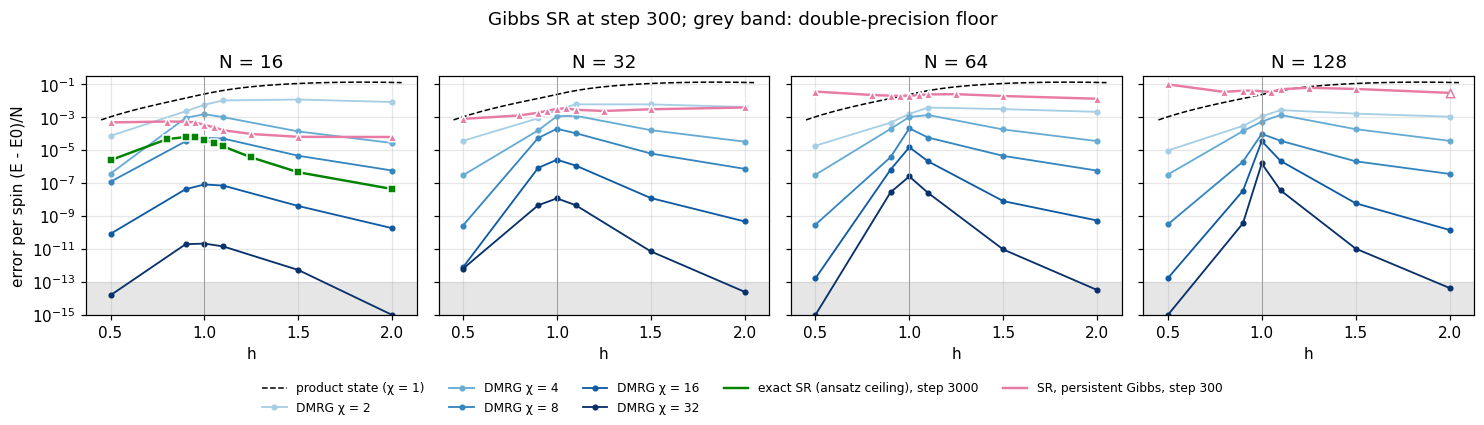

In [6]:
def dmrg_vs_h(step=300):
    Ns = sorted(dm.N.unique())
    fig, axes = plt.subplots(1, len(Ns), figsize=(3.4 * len(Ns), 3.8), sharey=True, squeeze=False)
    hf = np.linspace(0.45, 2.05, 81)
    vm = {arm: vmc_at(arm, st) for arm, st in (("exact_sr", 3000), ("gibbs", step))}
    for a, N in zip(axes[0], Ns):
        shade_floor(a)
        a.plot(hf, [mf_err(N, h) for h in hf], "k--", lw=1, label="product state (χ = 1)")
        for chi in CHIS:
            d = dm[(dm.N == N) & (dm.chi == chi)]
            a.plot(d.h, d.err_plot, "-o", color=chi_color[chi], ms=3, lw=1.2, label=f"DMRG χ = {chi}")
        for arm, v in vm.items():
            if N not in v.index.get_level_values("N"):
                continue
            g = v.loc[N]
            lab = f"{LABELS[arm]}, step {3000 if arm == 'exact_sr' else step}"
            a.plot(g.index, g.err, color=COLORS[arm], lw=1.6, label=lab)
            full = g.n >= 3
            a.scatter(g.index[full], g.err[full], color=COLORS[arm], marker=MARKERS[arm], s=30, ec="white", zorder=3)
            a.scatter(g.index[~full], g.err[~full], fc="white", ec=COLORS[arm], marker=MARKERS[arm], s=30, zorder=3)
        a.set_yscale("log"); a.set_title(f"N = {N}"); a.set_xlabel("h"); a.axvline(1, color="0.6", lw=0.6)
    axes[0, 0].set_ylabel("error per spin (E - E0)/N"); axes[0, 0].set_ylim(1e-15, 0.3)
    handles, labels = {}, []
    for a in axes[0]:
        for hd, lb in zip(*a.get_legend_handles_labels()):
            handles.setdefault(lb, hd)
    fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=5, fontsize=8, frameon=False)
    fig.suptitle(f"Gibbs SR at step {step}; grey band: double-precision floor")
    fig.tight_layout(rect=(0, 0.1, 1, 1))

dmrg_vs_h(300)

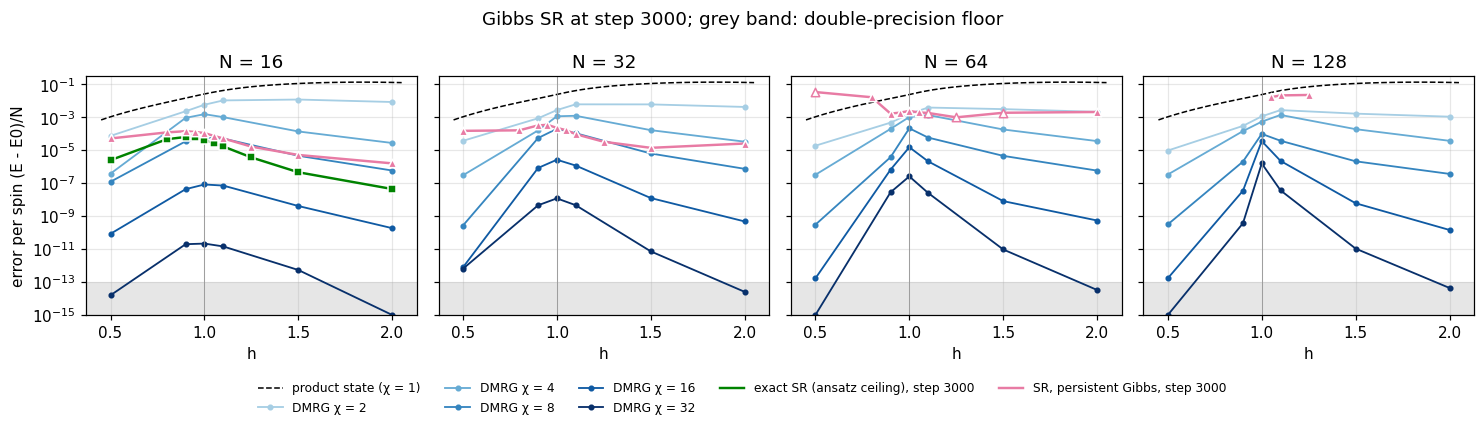

In [7]:
dmrg_vs_h(3000)

### 2.2 Accuracy vs wall time
The practical comparison: how much accuracy each method buys per second. Each VMC line is one seed through its
evaluated checkpoints (marker size grows with SR step; one seed per panel labelled 100/300/1k/3k); each DMRG point is
one χ. A line has 1–4 dots depending on how far that run has been extended and evaluated. Lower-left wins.

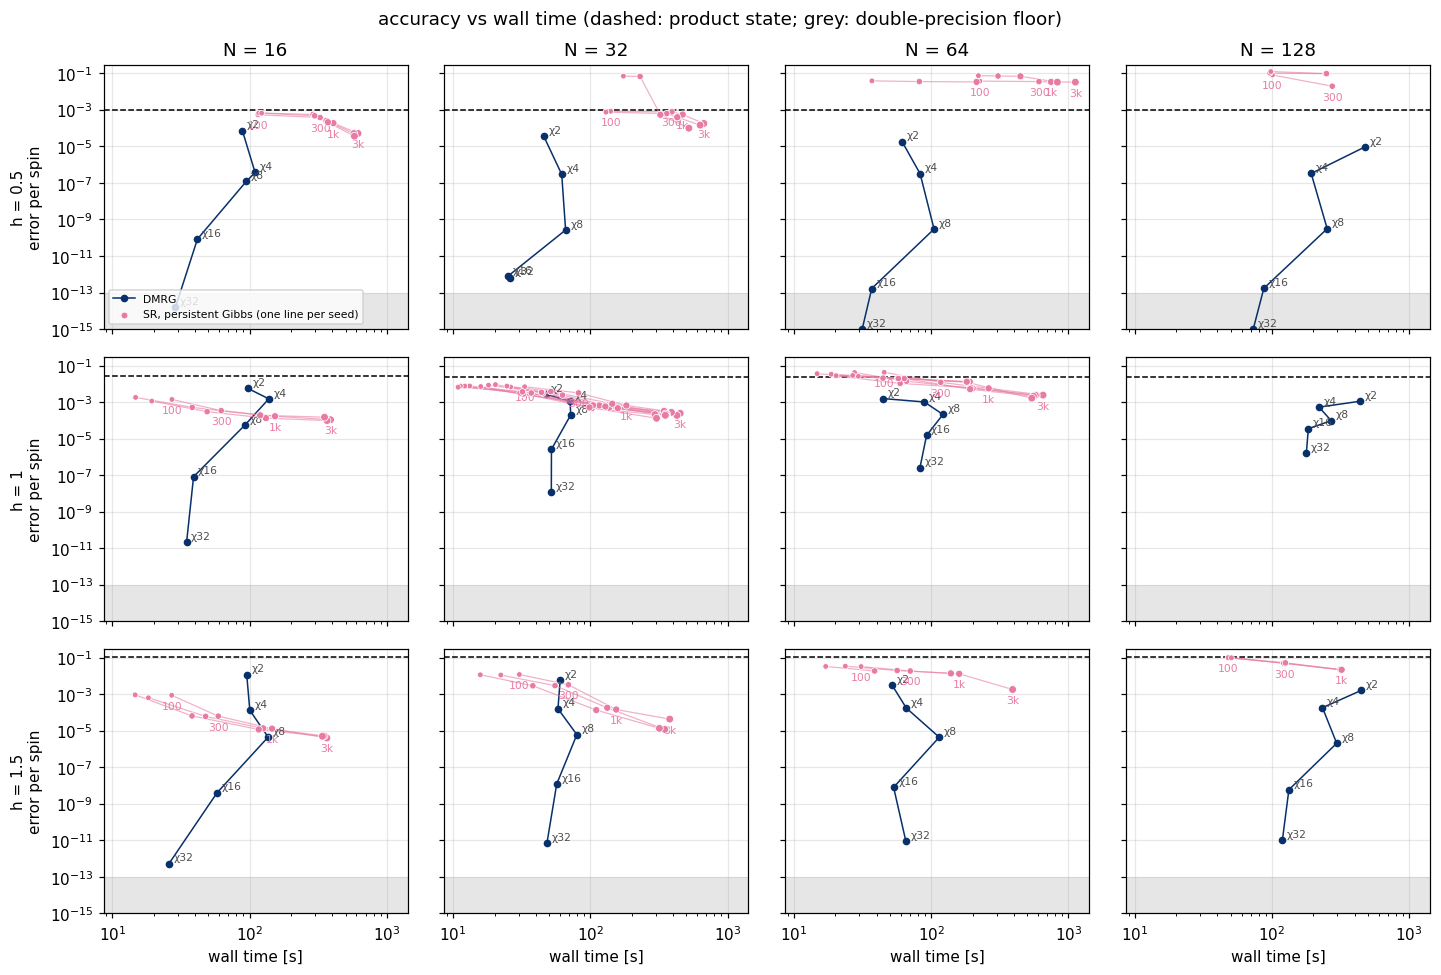

In [8]:
STEP_SIZE = lambda step: 6 + 8 * np.log10(np.asarray(step) / 100 * 10)  # 100 -> 14, 300 -> 18, 1k -> 22, 3k -> 26

def cost_plot(hs=(0.5, 1.0, 1.5), arm="gibbs"):
    Ns = sorted(dm.N.unique())
    fig, axes = plt.subplots(len(hs), len(Ns), figsize=(3.3 * len(Ns), 3.0 * len(hs)), sharex=True, sharey=True,
                             squeeze=False)
    for i, h in enumerate(hs):
        for j, N in enumerate(Ns):
            a = axes[i, j]
            shade_floor(a)
            a.axhline(mf_err(N, h), color="k", ls="--", lw=1)
            d = dm[(dm.N == N) & (dm.h == h)]
            a.plot(d.t_dmrg, d.err_plot, "-o", color=chi_color[CHIS[-1]], ms=4, lw=1, label="DMRG")
            for _, r in d.iterrows():
                a.annotate(f"χ{int(r.chi)}", (r.t_dmrg, r.err_plot), fontsize=7, color="0.3",
                           xytext=(3, 2), textcoords="offset points")
            v = df[(df.arm == arm) & (df.N == N) & (df.h == h)].dropna(subset=["err"])
            longest = v.groupby("seed").size().idxmax() if len(v) else None
            for k, (s, g) in enumerate(v.groupby("seed")):
                g = g.sort_values("step")
                a.plot(g.wall_s, g.err, "-", color=COLORS[arm], lw=0.8, alpha=0.6)
                a.scatter(g.wall_s, g.err, s=STEP_SIZE(g.step), color=COLORS[arm], zorder=3, lw=0.5, ec="white",
                          label=f"{LABELS[arm]} (one line per seed)" if k == 0 else None)
                if s == longest:  # name the checkpoints on one run per panel
                    for _, r in g.iterrows():
                        a.annotate(f"{r.step:g}" if r.step < 1000 else f"{r.step / 1000:g}k", (r.wall_s, r.err),
                                   fontsize=7, color=COLORS[arm], xytext=(0, -9), textcoords="offset points",
                                   ha="center")
            a.set_xscale("log"); a.set_yscale("log")
            if i == 0: a.set_title(f"N = {N}")
            if j == 0: a.set_ylabel(f"h = {h:g}\nerror per spin")
            if i == len(hs) - 1: a.set_xlabel("wall time [s]")
    axes[0, 0].set_ylim(1e-15, 0.3)
    axes[0, 0].legend(fontsize=7, loc="lower left")
    fig.suptitle("accuracy vs wall time (dashed: product state; grey: double-precision floor)")
    fig.tight_layout()

cost_plot()

### 2.3 Summary table at the critical point h = 1
Per N: product-state error, DMRG error and time at each χ, and Gibbs-SR error (median over seeds, n in brackets)
and training time at steps 300 and 3000; exact SR (ceiling) where it exists.

In [9]:
def summary(h=1.0):
    rows = {}
    for N in sorted(set(dm.N) | set(df.N)):
        r = {"product state": f"{mf_err(N, h):.1e}"}
        for _, d in dm[(dm.N == N) & (dm.h == h)].iterrows():
            r[f"DMRG χ={d.chi}"] = f"{d.err:.1e} ({d.t_dmrg:.0f} s)"
        for arm, st in (("gibbs", 300), ("gibbs", 3000), ("exact_sr", 3000)):
            v = vmc_at(arm, st)
            if (N, h) in v.index:
                x = v.loc[(N, h)]
                r[f"{arm} {st}"] = f"{x.err:.1e} ({x.wall_s:.0f} s, n={int(x.n)})"
        rows[N] = r
    t = pd.DataFrame(rows).T
    cols = ["product state"] + [f"DMRG χ={c}" for c in CHIS] + ["gibbs 300", "gibbs 3000", "exact_sr 3000"]
    return t.reindex(columns=[c for c in cols if c in t]).fillna("")

summary(1.0)

,product state,DMRG χ=2,DMRG χ=4,DMRG χ=8,DMRG χ=16,DMRG χ=32,gibbs 300,gibbs 3000,exact_sr 3000
8,3.1e-02,,,,,,"7.2e-05 (30 s, n=3)","2.3e-05 (188 s, n=3)","7.9e-06 (13 s, n=3)"
16,2.5e-02,5.6e-03 (97 s),1.5e-03 (138 s),5.5e-05 (92 s),8.2e-08 (39 s),2.1e-11 (35 s),"3.4e-04 (49 s, n=3)","1.1e-04 (366 s, n=3)","4.3e-05 (397 s, n=3)"
32,2.4e-02,2.7e-03 (47 s),1.1e-03 (71 s),2.0e-04 (72 s),2.6e-06 (52 s),1.2e-08 (52 s),"3.2e-03 (41 s, n=10)","2.2e-04 (352 s, n=10)",
64,2.3e-02,1.6e-03 (44 s),1.0e-03 (89 s),2.1e-04 (122 s),1.5e-05 (92 s),2.5e-07 (83 s),"2.0e-02 (59 s, n=9)","2.4e-03 (573 s, n=5)",
128,2.3e-02,1.1e-03 (436 s),5.3e-04 (220 s),9.6e-05 (270 s),3.5e-05 (184 s),1.6e-06 (178 s),,,


### 2.4 Which DMRG χ matches the RBM's energy?
An *energy* equivalence, not a measure of the RBM's entanglement (equal energies do not imply equal states).
Per (N, h): median Gibbs error over the seeds that reached the step, entry `χ (n seeds)`. `MF/k` = worse than the
best product state (χ = 1) by a factor k; `>χmax` = better than every χ run at that (N, h). Periodic chains: an MPS needs a larger χ than with
open boundaries for the same accuracy.

In [10]:
def chi_equivalent(step, arm="gibbs"):
    v = vmc_at(arm, step)
    out = {}
    for (N, h), r in v.iterrows():
        d = dm[(dm.N == N) & (dm.h == h)]
        if d.empty:
            continue
        ok = d[d.err <= r.err].chi
        mf = mf_err(N, h)
        chi = (f"MF/{r.err / mf:.2g}" if r.err > mf else str(ok.min()) if len(ok) else f">{d.chi.max()}")
        out[(N, h)] = f"{chi} ({int(r.n)})"
    return pd.Series(out, dtype=object).unstack() if out else pd.DataFrame()

for st in (300, 3000):
    print(f"Gibbs SR step {st}"); display(chi_equivalent(st))

Gibbs SR step 300


,0.5,0.9,1.0,1.1,1.5,2.0
16,2 (3),8 (3),8 (3),8 (3),8 (3),4 (3)
32,2 (3),2 (10),2 (10),4 (10),4 (3),4 (3)
64,MF/34 (3),MF/1.5 (10),2 (9),2 (7),2 (3),2 (3)
128,MF/93 (3),MF/3 (3),NaN,MF/1.2 (3),2 (3),2 (1)


Gibbs SR step 3000


,0.5,0.9,1.0,1.1,1.5,2.0
16,4 (3),8 (3),8 (3),8 (3),8 (3),8 (3)
32,2 (3),4 (10),8 (10),16 (10),8 (3),8 (3)
64,MF/32 (2),2 (7),2 (5),4 (2),4 (1),4 (3)
128,NaN,NaN,NaN,2 (3),NaN,NaN


## 3. Impact of each ingredient
### 3.1 RBM error budget: ansatz → + Monte Carlo noise → + Markov chain
All three arms at the same SR step ($N\le16$, where all three exist). Factors > 1 are what each ingredient costs.

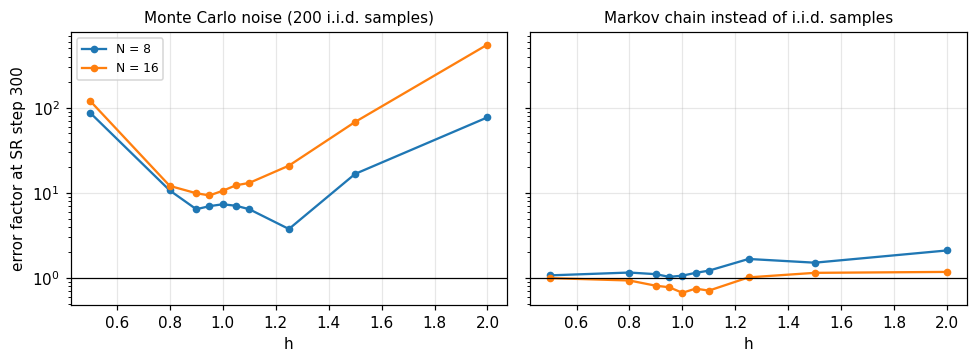

In [11]:
def error_budget(step=300):
    med = {arm: df[(df.arm == arm) & (df.step == step)].dropna(subset=["err"]).groupby(["N", "h"]).err.median()
           for arm in ("exact_sr", "exact", "gibbs")}
    t = pd.DataFrame({"ansatz (exact SR)": med["exact_sr"], "exact samples": med["exact"], "Gibbs": med["gibbs"]}).dropna()
    t["× noise (exact/exact SR)"] = t["exact samples"] / t["ansatz (exact SR)"]
    t["× MCMC (Gibbs/exact)"] = t["Gibbs"] / t["exact samples"]
    return t

budget = error_budget(300)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for a, col, title in ((ax[0], "× noise (exact/exact SR)", "Monte Carlo noise (200 i.i.d. samples)"),
                      (ax[1], "× MCMC (Gibbs/exact)", "Markov chain instead of i.i.d. samples")):
    for N, g in budget.groupby(level="N"):
        a.plot(g.index.get_level_values("h"), g[col], "-o", ms=4, label=f"N = {N}")
    a.axhline(1, color="k", lw=0.8); a.set_yscale("log"); a.set_xlabel("h"); a.set_title(title, fontsize=10)
ax[0].set_ylabel("error factor at SR step 300"); ax[0].legend(fontsize=8)
fig.tight_layout()
budget.style.format("{:.2e}", subset=budget.columns[:3]).format("{:.1f}", subset=budget.columns[3:])

Same three arms against h, with the product state as reference (rows: error per spin, relative error, ratio to the product state):

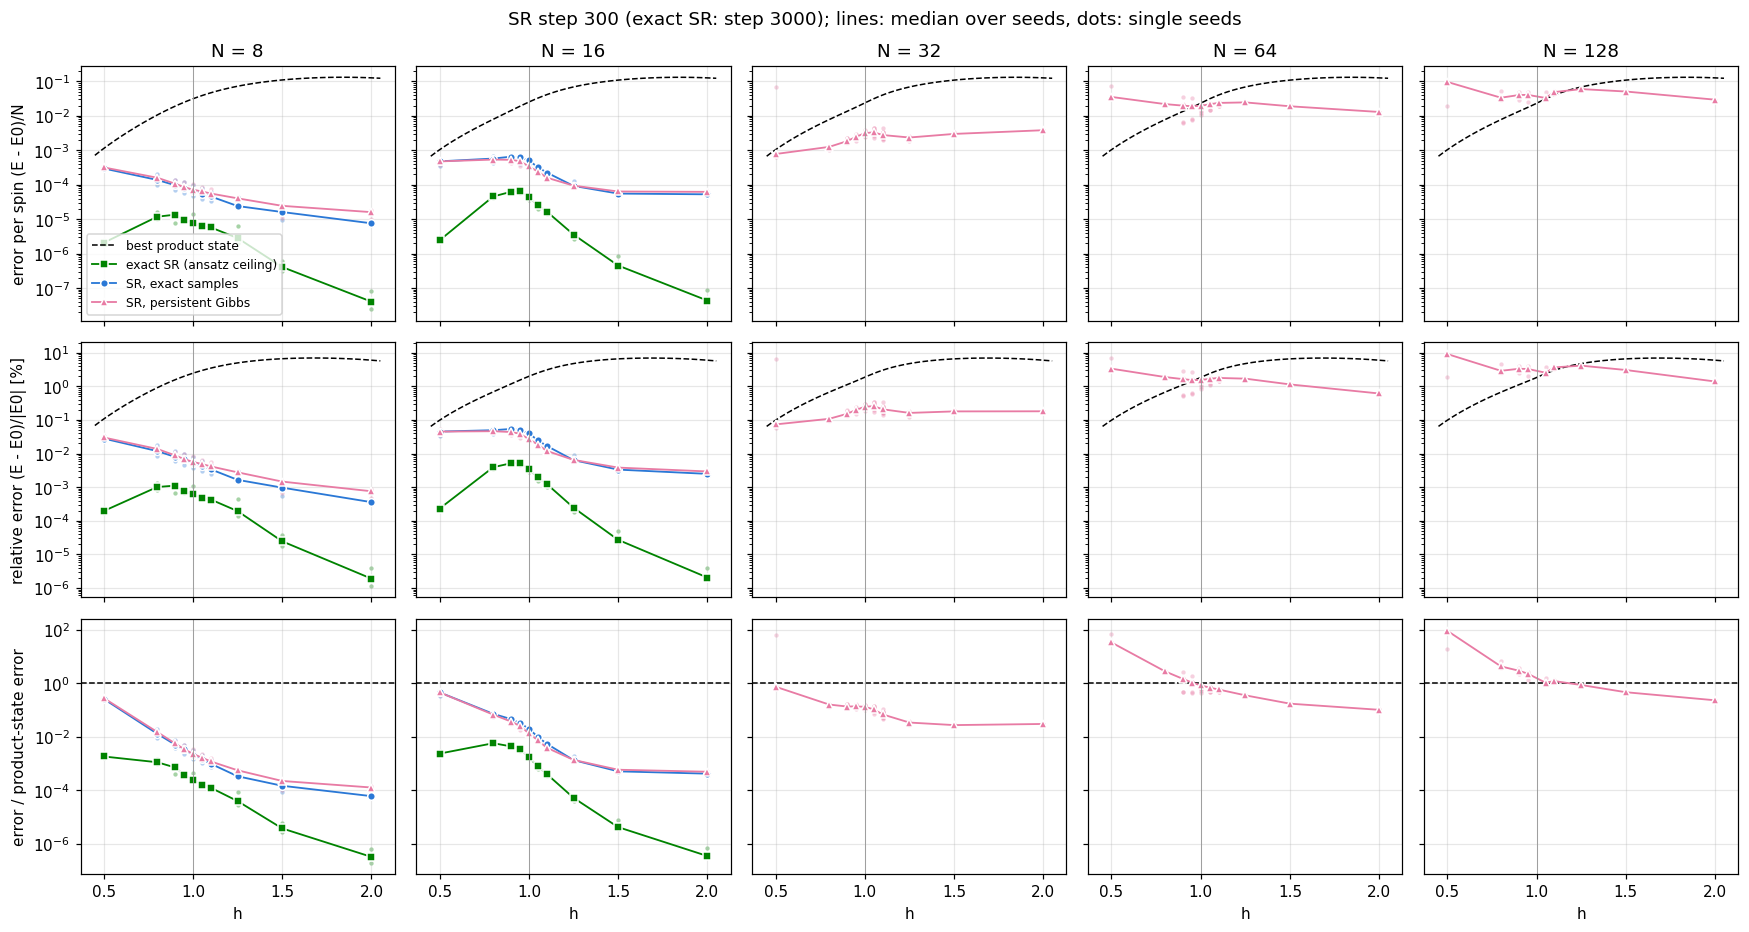

In [12]:
def panel_plot(step=300, ceiling_step=3000, variants=("exact_sr", "exact", "gibbs")):
    Ns = sorted(df[df.arm.isin(variants)].N.unique())
    fig, axes = plt.subplots(3, len(Ns), figsize=(3.2 * len(Ns), 8.6), sharex=True, sharey="row", squeeze=False)
    hf = np.linspace(0.45, 2.05, 81)
    for j, N in enumerate(Ns):
        top, mid, bot = axes[0, j], axes[1, j], axes[2, j]
        top.plot(hf, [mf_err(N, h) for h in hf], "k--", lw=1, label="best product state")
        mid.plot(hf, [100 * mf_rel(N, h) for h in hf], "k--", lw=1)
        bot.axhline(1, color="k", ls="--", lw=1)
        for arm in variants:
            st = ceiling_step if arm == "exact_sr" else step
            d = df[(df.arm == arm) & (df.N == N) & (df.step == st)].dropna(subset=["err"])
            if d.empty:
                continue
            top.scatter(d.h, d.err, s=8, color=COLORS[arm], alpha=0.35, lw=0)
            mid.scatter(d.h, 100 * d.rel_err, s=8, color=COLORS[arm], alpha=0.35, lw=0)
            bot.scatter(d.h, d.err / d.mf_err, s=8, color=COLORS[arm], alpha=0.35, lw=0)
            g = d.groupby("h").agg(err=("err", "median"), rel=("rel_err", "median"), mf=("mf_err", "first"))
            kw = dict(color=COLORS[arm], marker=MARKERS[arm], ms=5, lw=1.2, mec="white")
            top.plot(g.index, g.err, label=LABELS[arm], **kw)
            mid.plot(g.index, 100 * g.rel, **kw)
            bot.plot(g.index, g.err / g.mf, **kw)
        top.set_title(f"N = {N}"); bot.set_xlabel("h")
        for a in (top, mid, bot):
            a.set_yscale("log"); a.axvline(1, color="0.6", lw=0.6)
    axes[0, 0].set_ylabel("error per spin (E - E0)/N"); axes[1, 0].set_ylabel("relative error (E - E0)/|E0| [%]")
    axes[2, 0].set_ylabel("error / product-state error")
    axes[0, 0].legend(fontsize=8, loc="lower left")
    fig.suptitle(f"SR step {step}" + (f" (exact SR: step {ceiling_step})" if "exact_sr" in variants else "")
                 + "; lines: median over seeds, dots: single seeds")
    fig.tight_layout()

panel_plot(step=300)

### 3.2 Impact of system size N
Error per spin vs N at fixed h. A method whose error per spin stays flat scales; one whose error grows with N does not.
Product state and fixed-χ DMRG are (nearly) size-independent per spin; Gibbs-trained RBMs at a fixed step budget are not.

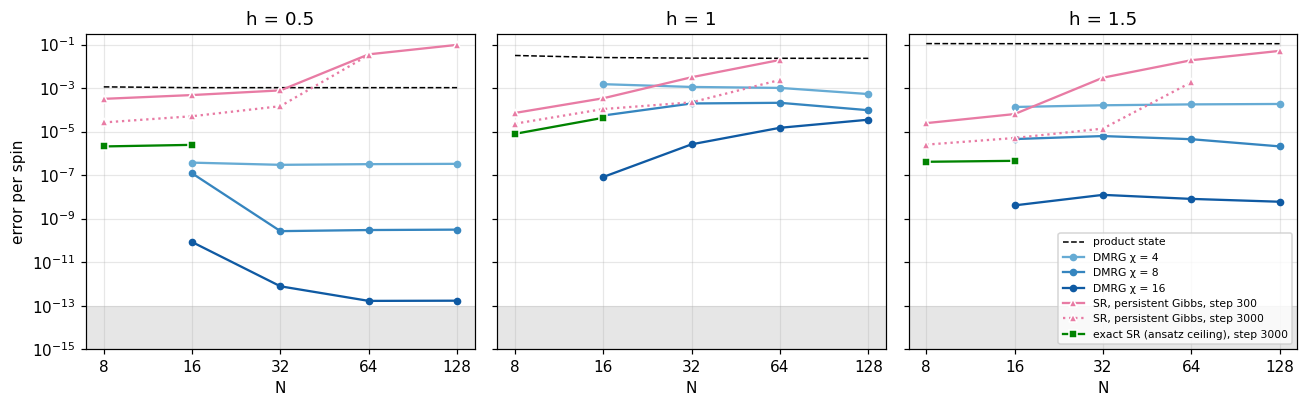

In [13]:
def vs_N(hs=(0.5, 1.0, 1.5), chis=(4, 8, 16)):
    fig, axes = plt.subplots(1, len(hs), figsize=(4 * len(hs), 3.8), sharey=True, squeeze=False)
    Ns = sorted(set(df.N) | set(dm.N))
    for a, h in zip(axes[0], hs):
        shade_floor(a)
        a.plot(Ns, [mf_err(N, h) for N in Ns], "k--", lw=1, label="product state")
        for chi in chis:
            d = dm[(dm.h == h) & (dm.chi == chi)]
            if len(d):
                a.plot(d.N, d.err_plot, "-o", ms=4, color=chi_color.get(chi, "C0"), label=f"DMRG χ = {chi}")
        for arm, st, ls in (("gibbs", 300, "-"), ("gibbs", 3000, ":"), ("exact_sr", 3000, "-")):
            v = vmc_at(arm, st)
            if h in v.index.get_level_values("h"):
                g = v.xs(h, level="h")
                a.plot(g.index, g.err, ls, marker=MARKERS[arm], ms=5, color=COLORS[arm], mec="white",
                       label=f"{LABELS[arm]}, step {st}")
        a.set_xscale("log", base=2); a.set_yscale("log"); a.set_xticks(Ns, [str(n) for n in Ns])
        a.set_title(f"h = {h:g}"); a.set_xlabel("N")
    axes[0, 0].set_ylabel("error per spin"); axes[0, 0].set_ylim(1e-15, 0.3)
    axes[0, -1].legend(fontsize=7, loc="lower right")
    fig.tight_layout()

vs_N()

### 3.3 Impact of the bond dimension χ (DMRG)
Error per spin vs χ, one line per N. The slope is the payoff of entanglement: steepest away from $h=1$, flattest at
the critical point and for larger N (periodic chains also need a larger χ than open ones).

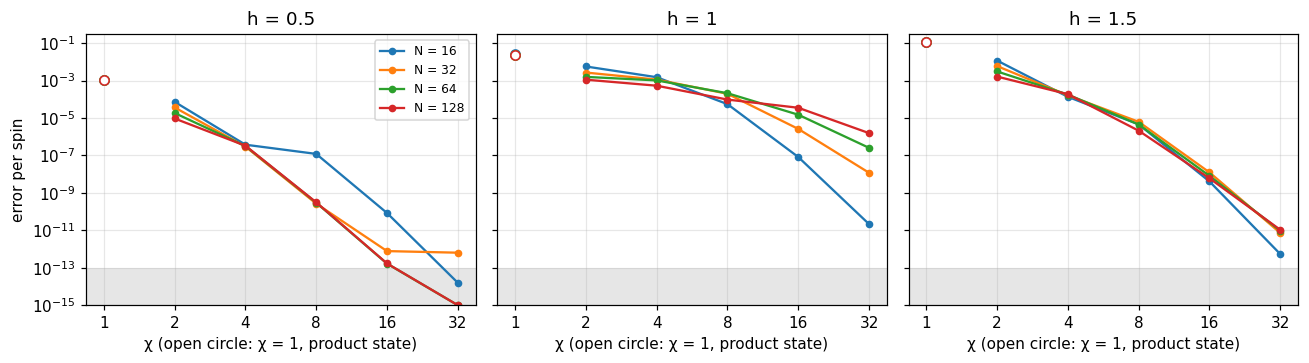

In [14]:
hs_chi = (0.5, 1.0, 1.5)
fig, axes = plt.subplots(1, len(hs_chi), figsize=(4 * len(hs_chi), 3.4), sharey=True)
for a, h in zip(axes, hs_chi):
    shade_floor(a)
    for i, (N, d) in enumerate(dm[dm.h == h].groupby("N")):
        line, = a.plot(d.chi, d.err_plot, "-o", ms=4, label=f"N = {N}")
        a.plot([1], [mf_err(N, h)], "o", mfc="white", color=line.get_color())  # χ = 1: product state
    a.set_xscale("log", base=2); a.set_yscale("log"); a.set_xlabel("χ (open circle: χ = 1, product state)")
    a.set_xticks([1] + CHIS, [str(c) for c in [1] + CHIS])
    a.set_title(f"h = {h:g}")
axes[0].set_ylabel("error per spin"); axes[0].set_ylim(1e-15, 0.3); axes[0].legend(fontsize=8)
fig.tight_layout()

### 3.4 Impact of training length (RBM)
Median error vs SR step, one column per N, one line per h; dashed: product state. Then the raw training
trajectories (sampled energy during SR).

Median over seeds against SR step, one column per N, one line per h; top: error per spin, bottom: relative
error; dashed: product state.
Checkpoints at 100, 300, 1000, 3000 steps (phase 2 extends phase 1).

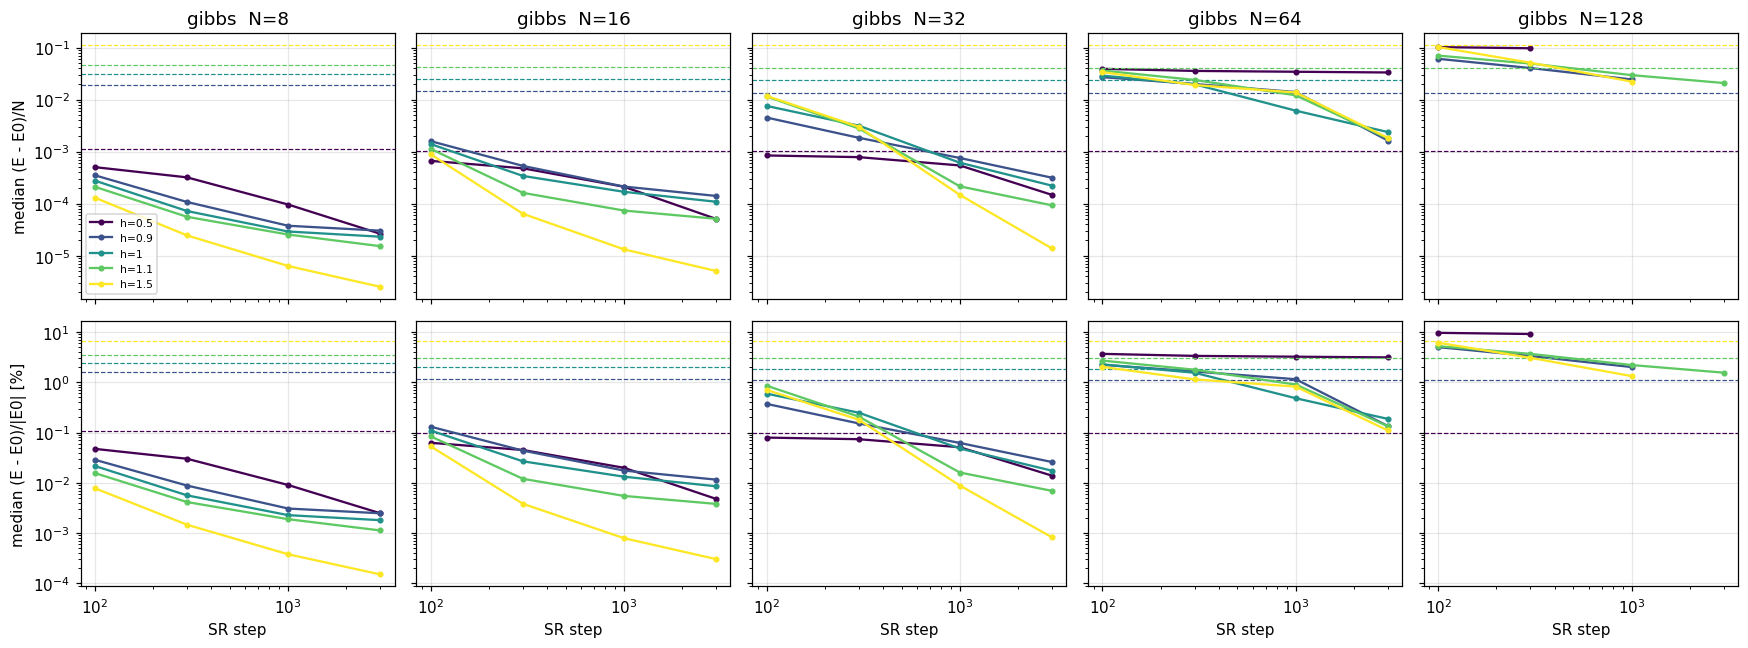

In [15]:
def convergence(arm="gibbs", hs=(0.5, 0.9, 1.0, 1.1, 1.5)):
    Ns = sorted(df[df.arm == arm].N.unique())
    fig, axes = plt.subplots(2, len(Ns), figsize=(3.2 * len(Ns), 6), sharey="row", sharex=True, squeeze=False)
    cmap = plt.get_cmap("viridis")
    for j, N in enumerate(Ns):
        for i, h in enumerate(hs):
            d = df[(df.arm == arm) & (df.N == N) & (df.h == h)].dropna(subset=["err"])
            if d.empty:
                continue
            g = d.groupby("step").agg(err=("err", "median"), rel=("rel_err", "median"))
            c = cmap(i / max(len(hs) - 1, 1))
            axes[0, j].plot(g.index, g.err, "o-", color=c, ms=3, label=f"h={h:g}")
            axes[0, j].axhline(mf_err(N, h), color=c, ls="--", lw=0.8)
            axes[1, j].plot(g.index, 100 * g.rel, "o-", color=c, ms=3)
            axes[1, j].axhline(100 * mf_rel(N, h), color=c, ls="--", lw=0.8)
        axes[0, j].set_title(f"{arm}  N={N}"); axes[1, j].set_xlabel("SR step")
        for a in axes[:, j]:
            a.set_xscale("log"); a.set_yscale("log")
    axes[0, 0].set_ylabel("median (E - E0)/N"); axes[1, 0].set_ylabel("median (E - E0)/|E0| [%]")
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()

convergence()

Signed, on a symmetric-log axis: the per-step 200-sample estimates scatter **below** E0 (their noise is larger
than the remaining error), so the thin lines are not convergence; the thick lines are 20-step running means.
Exact SR has no sampling noise.

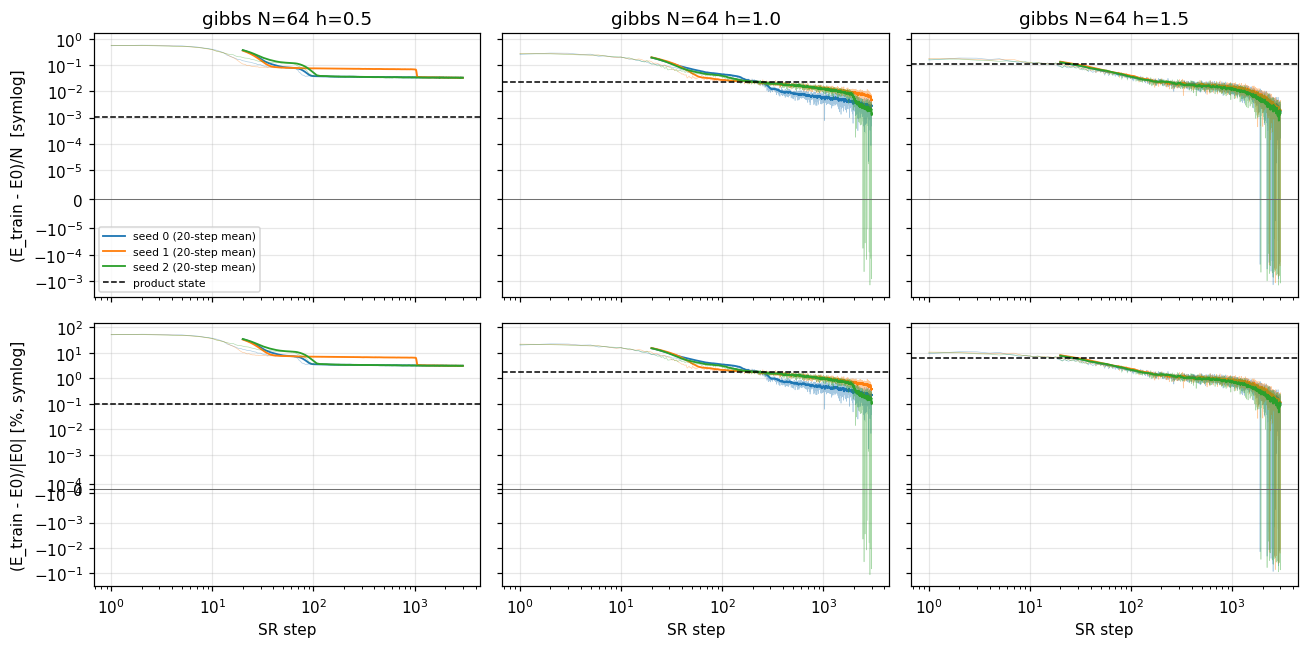

In [16]:
def trajectories(arm, N, hs=(0.5, 1.0, 1.5), seeds=(0, 1, 2)):
    fig, ax = plt.subplots(2, len(hs), figsize=(4 * len(hs), 6), sharey="row", sharex=True, squeeze=False)
    for j, h in enumerate(hs):
        m = TransverseFieldIsing1D(N, h); e0 = m.exact_ground_energy()
        for row, scale, ref in ((0, 1 / N, mf_err(N, h)), (1, 100 / abs(e0), 100 * mf_rel(N, h))):
            a = ax[row, j]
            for s in seeds:
                f = DATA / "state" / f"{arm}_N{N}_h{h:g}_s{s}.npz"
                if f.exists():
                    E = (np.load(f)["energy"] - e0) * scale
                    x = np.arange(1, len(E) + 1)
                    line, = a.plot(x, E, lw=0.4, alpha=0.4)
                    w = 20 if len(E) >= 40 else 1
                    a.plot(x[w - 1:], np.convolve(E, np.ones(w) / w, "valid"), lw=1.2, color=line.get_color(),
                           label=f"seed {s} ({w}-step mean)")
            a.axhline(ref, color="k", ls="--", lw=1, label="product state")
            a.axhline(0, color="0.4", lw=0.6)
            a.set_yscale("symlog", linthresh=1e-5 * scale * N); a.set_xscale("log")
        ax[0, j].set_title(f"{arm} N={N} h={h}"); ax[1, j].set_xlabel("SR step")
    ax[0, 0].set_ylabel("(E_train - E0)/N  [symlog]"); ax[1, 0].set_ylabel("(E_train - E0)/|E0| [%, symlog]")
    ax[0, 0].legend(fontsize=7)
    fig.tight_layout()

trajectories("gibbs", 64)

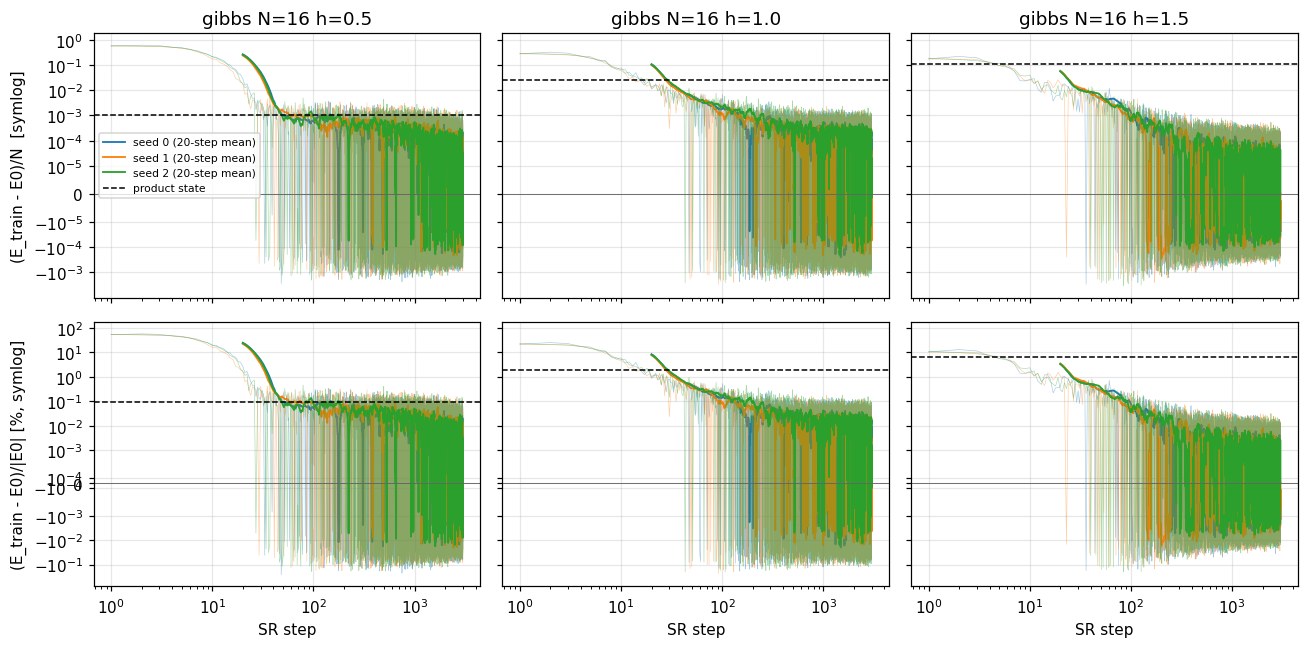

In [17]:
trajectories("gibbs", 16)

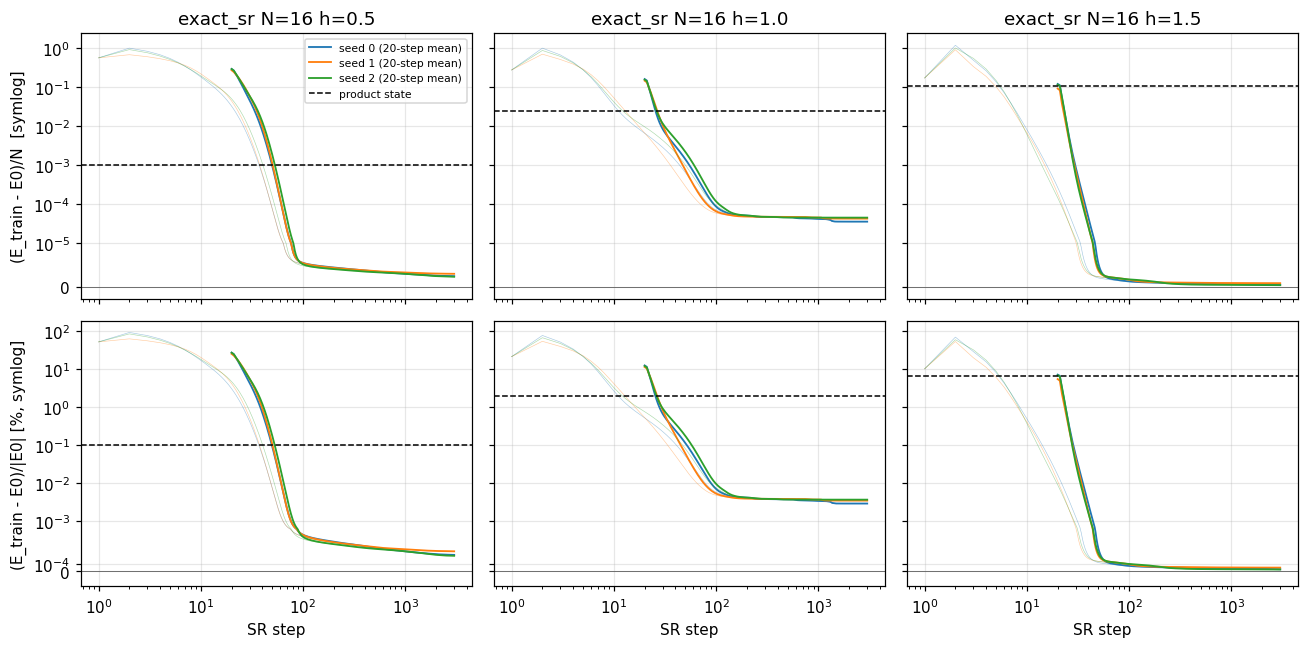

In [18]:
trajectories("exact_sr", 16)

### 3.5 Impact of RBM variants (Gibbs)
Product-state initialisation (`gibbs_mfinit`) and twice the hidden units (`gibbs_a2`) against the plain run,
at the latest checkpoint all variants share.

arm            gibbs  gibbs_a2  gibbs_mfinit
N   h                                       
8   0.50      43.107       NaN           NaN
    0.80     401.741       NaN           NaN
    0.90     633.802       NaN           NaN
    0.95    1022.759       NaN           NaN
    1.00    1359.909       NaN           NaN
    1.05    2066.968       NaN           NaN
    1.10    3083.261       NaN           NaN
    1.25    9730.855       NaN           NaN
    1.50   43927.696       NaN           NaN
    2.00  150258.977       NaN           NaN
16  0.50      20.558       NaN           NaN
    0.80      67.232       NaN           NaN
    0.90     101.799       NaN           NaN
    0.95     152.675       NaN           NaN
    1.00     232.733       NaN           NaN
    1.05     451.372       NaN           NaN
    1.10     809.321       NaN           NaN
    1.25    4268.979       NaN           NaN
    1.50   21589.614       NaN           NaN
    2.00   81150.073       NaN           NaN
32  0.50       7.094       NaN         7.986
    0.80      49.293       NaN        14.024
    0.90      43.107    50.156        11.536
    0.95      52.336       NaN        10.178
    1.00     107.273    77.497           NaN
    1.05     197.927       NaN        53.089
    1.10     436.185   557.099           NaN
    1.25    2165.118       NaN           NaN
    1.50    7964.919  2405.600           NaN
    2.00    5063.859       NaN           NaN
64  0.50       0.031       NaN           NaN
    0.80       0.487       NaN           NaN
    0.90       8.265       NaN           NaN
    0.95       9.457       NaN           NaN
    1.00       9.844       NaN           NaN
    1.05      16.206       NaN           NaN
    1.10      22.734       NaN           NaN
    1.25      71.161       NaN           NaN
    1.50      59.556       NaN           NaN
    2.00      62.026       NaN           NaN
128 1.05       1.935       NaN           NaN
    1.10       1.941       NaN           NaN
    1.25       3.134       NaN           NaN

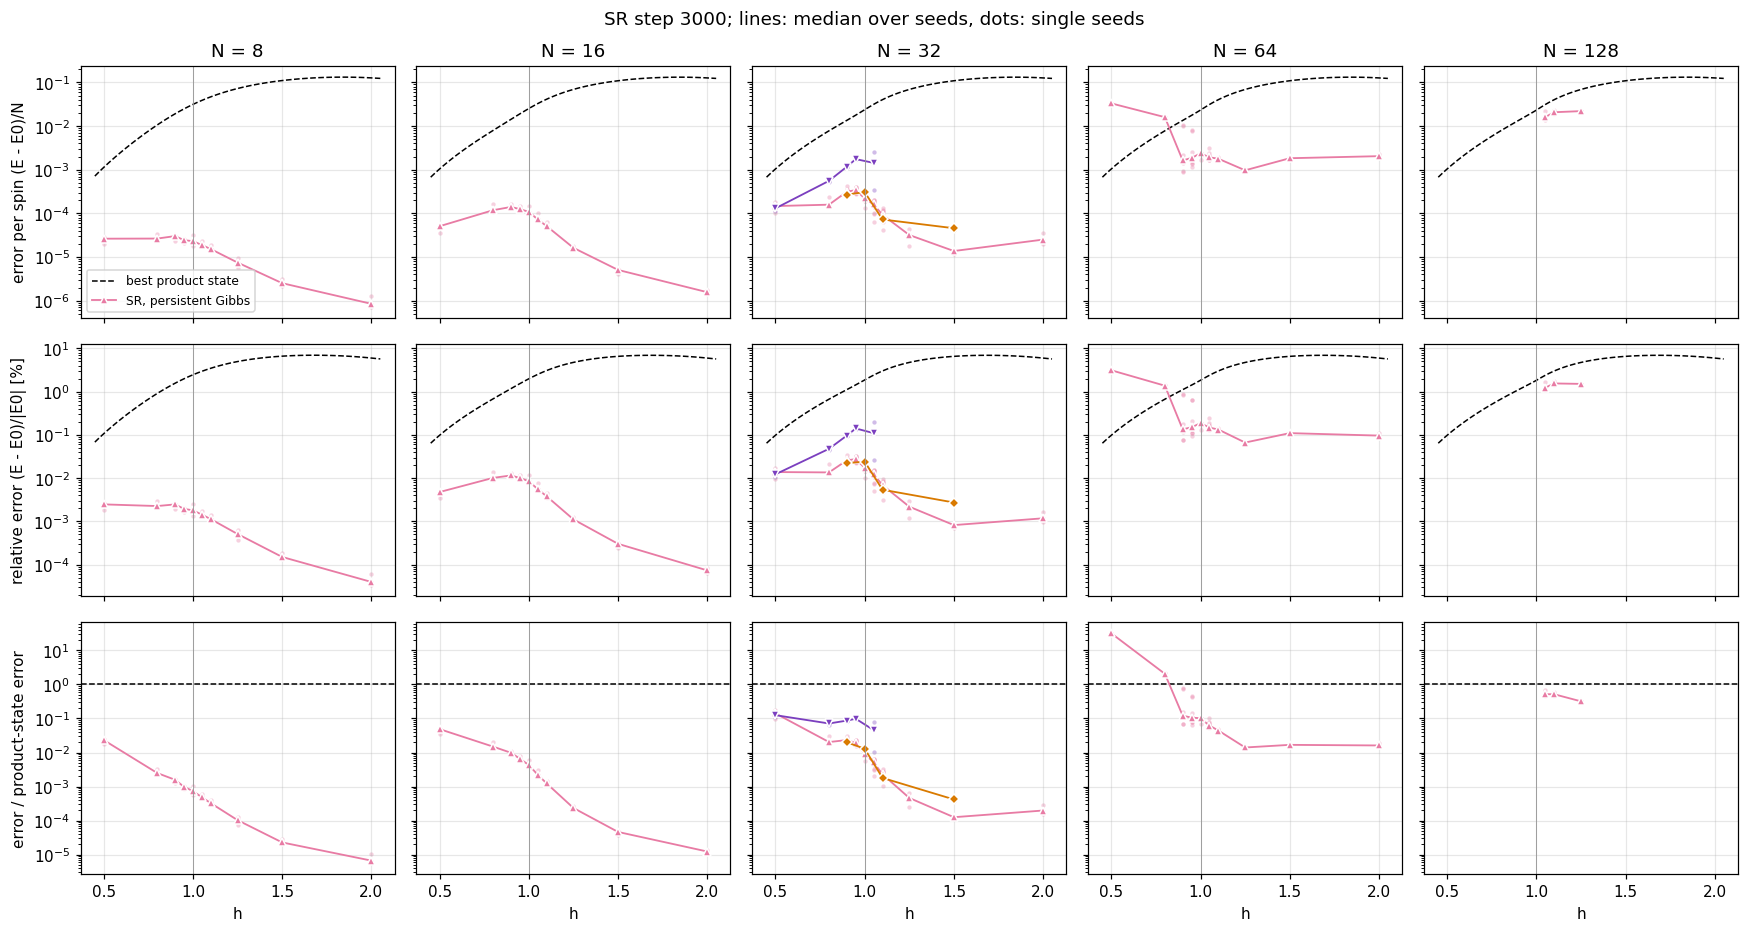

In [19]:
V = ("gibbs", "gibbs_mfinit", "gibbs_a2")
have = df[df.arm.isin(V)].dropna(subset=["err"])
if have.arm.nunique() > 1:
    common = sorted(set.intersection(*(set(have[have.arm == v].step) for v in have.arm.unique())))
    panel_plot(step=common[-1], variants=tuple(v for v in V if v in set(have.arm)))
    display(have[have.step == common[-1]].groupby(["N", "h", "arm"]).gain_over_mf.median().unstack("arm"))
else:
    print("no variant runs evaluated yet")

## 4. Validation
### 4.1 Are the DMRG samples correct?
⟨σᶻᵢσᶻᵢ₊₁⟩ averaged over all N bonds, from the 10⁴ samples vs from the MPS; z = difference / standard error of the
sample mean (from the per-sample bond averages, which are i.i.d.). z should look standard normal (about 95 % within 2).
Exactness of the sampler was also checked against full |ψ|² histograms (χ² test, N = 6–8) in the code audit.
This validates the sampler against *its* MPS, not against |ψ₀|². One known difference: for h < 1 DMRG returns a
symmetry-broken state (all samples m > 0), while the finite-N ground state has both signs equally; `sample()` now flips
each sample globally with probability 1/2 (`z2_symmetrize`). The zz check is Z2-even and blind to this.

120 checks, |z| < 2: 95%, max |z| = 2.80, mean z = -0.08


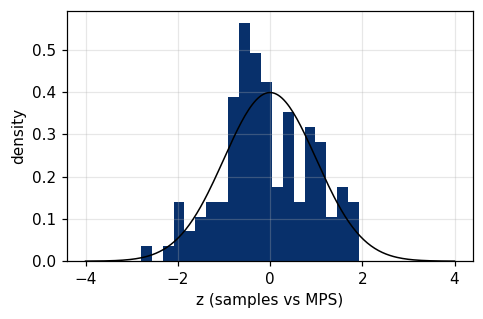

In [20]:
chk = dm.assign(z=lambda x: (x.zz_samples - x.zz_mps) / x.zz_samples_se)
print(f"{len(chk)} checks, |z| < 2: {(chk.z.abs() < 2).mean():.0%}, max |z| = {chk.z.abs().max():.2f}, "
      f"mean z = {chk.z.mean():+.2f}")
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.hist(chk.z, bins=20, color=chi_color[CHIS[-1]], density=True)
zz = np.linspace(-4, 4, 200); ax.plot(zz, np.exp(-zz ** 2 / 2) / np.sqrt(2 * np.pi), "k", lw=1)
ax.set_xlabel("z (samples vs MPS)"); ax.set_ylabel("density"); fig.tight_layout()

## Appendix A — product state vs trained RBMs in detail
The analyses written for the reviewer's question (is $h=0.5$ indistinguishable from a product state?).

### A.1 SR step 100

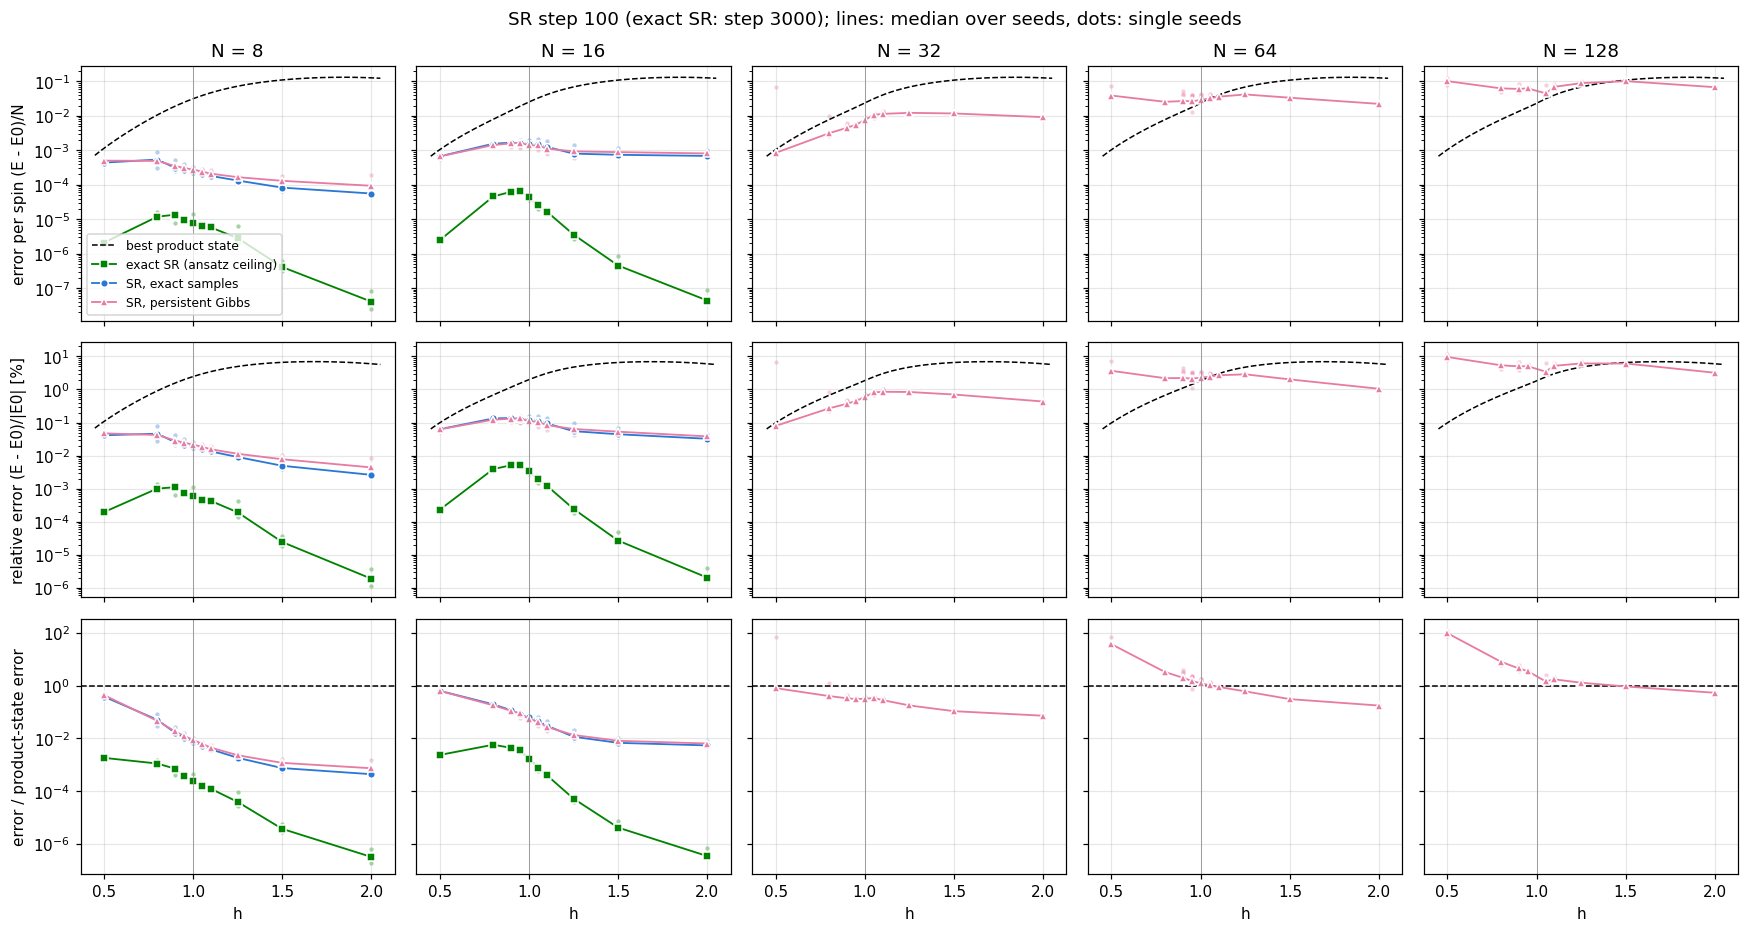

In [21]:
panel_plot(step=100)

### A.2 How many times better than the product state? (median over seeds; < 1 = worse)


In [22]:
def gain_table(step=300, ceiling_step=3000):
    d = df[((df.arm == "exact_sr") & (df.step == ceiling_step)) | ((df.arm != "exact_sr") & (df.step == step))]
    t = d.groupby(["arm", "N", "h"]).gain_over_mf.median().unstack("h")
    return t.reindex(["exact_sr", "exact", "gibbs"], level="arm")

def show_gain(step=300):
    t = gain_table(step)
    L = np.nanmax(np.abs(np.log10(t.values)))  # diverging scale centred on 1x, spanning all values
    return t.style.format("{:.3g}", na_rep="").background_gradient(cmap="RdYlGn", axis=None, vmin=-L, vmax=L,
                                                                   gmap=np.log10(t))

show_gain(300)

In [23]:
show_gain(100)

### A.3 Relative error (E - E0)/|E0| in % (median over seeds), with the product state in the first row


In [24]:
def rel_table(step=300, ceiling_step=3000):
    d = df[((df.arm == "exact_sr") & (df.step == ceiling_step)) | ((df.arm != "exact_sr") & (df.step == step))]
    t = 100 * d.groupby(["arm", "N", "h"]).rel_err.median().unstack("h")
    mf = 100 * df[df.N == df.N.max()].groupby("h").mf_rel_err.first().to_frame().T
    mf.index = pd.MultiIndex.from_tuples([("product state", df.N.max())], names=["arm", "N"])
    return pd.concat([mf, t])

rel_table(300).style.format("{:.2g}", na_rep="")

### A.4 N = 64 per seed — trapped or still improving?
`absm` = ⟨|m|⟩ and `dw` = mean number of domain walls of the trained network (global-flip evaluator).
References: `dw_GS` = ground-state domain walls, N(1 - ⟨σᶻσᶻ⟩)/2 from free fermions; `m_inf` = (1 - h²)^(1/8),
the thermodynamic-limit order parameter (h < 1), a rough guide to ⟨|m|⟩ at N = 64.
Compare like with like: a run with ground-state-like `dw` but `absm` far below `m_inf` has not ordered
(domains of both signs); `dw` well above `dw_GS` means too many domain walls (h = 0.5).

In [25]:
def dw_gs(N, h):
    k = np.pi * (2 * np.arange(N) + 1) / N
    zz = np.mean((1 - h * np.cos(k)) / np.sqrt(1 + h * h - 2 * h * np.cos(k)))  # -dE0/dJ per bond
    return N * (1 - zz) / 2

def per_seed(N=64, arm="gibbs"):
    d = df[(df.arm == arm) & (df.N == N)].assign(rel_pct=lambda x: 100 * x.rel_err).pivot_table(
        index=["h", "seed"], columns="step", values=["err", "rel_pct", "absm", "dw"])
    hs = d.index.get_level_values("h")
    d["dw_GS"] = [dw_gs(N, h) for h in hs]
    d["m_inf"] = [(1 - h * h) ** 0.125 if h < 1 else 0.0 for h in hs]
    d["mf_err"] = [mf_err(N, h) for h in hs]
    d["mf_rel_pct"] = [100 * mf_rel(N, h) for h in hs]
    return d  # err: per spin; rel_pct: relative error in %

per_seed(64)

absm                           dw                            err  \
step        100    300   1000   3000     100     300    1000    3000    100   
h   seed                                                                      
0.5 0     0.202  0.203  0.182  0.214   3.956   4.033   3.987   4.026  0.038   
    1     0.227  0.213  0.229  0.347   5.962   5.945   6.016   4.052  0.075   
    2     0.358  0.344  0.344    NaN   3.935   3.960   4.008     NaN  0.039   
0.8 0     0.077  0.095  0.106  0.129   7.069   7.278   7.435   7.568  0.026   
    1     0.147  0.168  0.174  0.178   7.222   7.195   7.366   7.659  0.026   
...         ...    ...    ...    ...     ...     ...     ...     ...    ...   
1.5 1     0.162  0.165  0.160    NaN  21.972  21.345  21.404     NaN  0.035   
    2     0.164  0.158    NaN    NaN  22.160  21.565     NaN     NaN  0.034   
2.0 0     0.135  0.133  0.136  0.136  24.886  24.499  24.329  23.890  0.022   
    1     0.139  0.134  0.133  0.136  24.850  24.430  24.255  23.860  0.023   
    2     0.129  0.140  0.140  0.134  24.941  24.394  24.345  23.883  0.021   

                              rel_pct                        dw_GS  m_inf  \
step        300   1000   3000     100    300   1000   3000                  
h   seed                                                                    
0.5 0     0.036  0.034  0.033   3.544  3.338  3.218  3.124   2.105  0.965   
    1     0.072  0.069  0.033   7.072  6.768  6.506  3.111   2.105  0.965   
    2     0.036  0.034    NaN   3.665  3.340  3.199    NaN   2.105  0.965   
0.8 0     0.022  0.019  0.016   2.197  1.890  1.635  1.406   5.998  0.880   
    1     0.022  0.019  0.016   2.228  1.853  1.601  1.374   5.998  0.880   
...         ...    ...    ...     ...    ...    ...    ...     ...    ...   
1.5 1     0.020  0.014    NaN   2.080  1.205  0.839    NaN  20.610  0.000   
    2     0.019    NaN    NaN   2.018  1.138    NaN    NaN  20.610  0.000   
2.0 0     0.013  0.011  0.002   1.050  0.612  0.499  0.095  23.723  0.000   
    1     0.013  0.010  0.002   1.065  0.630  0.461  0.110  23.723  0.000   
    2     0.013  0.011  0.002   1.006  0.594  0.494  0.096  23.723  0.000   

         mf_err mf_rel_pct  
step                        
h   seed                    
0.5 0     0.001      0.098  
    1     0.001      0.098  
    2     0.001      0.098  
0.8 0     0.008      0.669  
    1     0.008      0.669  
...         ...        ...  
1.5 1     0.109      6.545  
    2     0.109      6.545  
2.0 0     0.127      5.975  
    1     0.127      5.975  
    2     0.127      5.975  

[61 rows x 20 columns]

### A.5 Where does a trained network beat the product state?
Fraction of seeds with error below the product-state error, per N and h, at each SR step (Gibbs).

In [26]:
def beat_fraction(arm="gibbs"):
    d = df[df.arm == arm].dropna(subset=["err"]).assign(beats=lambda x: x.err < x.mf_err)
    t = d.groupby(["N", "step", "h"]).beats.agg(lambda b: f"{b.sum()}/{b.size}").unstack("h")
    return t

beat_fraction("gibbs")

h        0.50 0.80   0.90   0.95   1.00   1.05   1.10 1.25 1.50 2.00
N   step                                                            
8   100   3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
    300   3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
    1000  3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
    3000  3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
16  100   3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
    300   3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
    1000  3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
    3000  3/3  3/3    3/3    3/3    3/3    3/3    3/3  3/3  3/3  3/3
32  100   2/3  2/3  10/10  10/10  10/10  10/10  10/10  3/3  3/3  3/3
    300   2/3  3/3  10/10  10/10  10/10  10/10  10/10  3/3  3/3  3/3
    1000  3/3  3/3  10/10  10/10  10/10  10/10  10/10  3/3  3/3  3/3
    3000  3/3  3/3  10/10  10/10  10/10  10/10  10/10  3/3  3/3  3/3
64  100   0/3  0/3   0/10   1/10    0/9   3/10    6/7  3/3  3/3  3/3
    300   0/3  0/3   2/10   2/10    9/9  10/10    7/7  3/3  3/3  3/3
    1000  0/3  0/3    3/7  10/10    7/7  10/10    3/3  2/2  2/2  3/3
    3000  0/2  0/3    7/7  10/10    5/5  10/10    2/2  1/1  1/1  3/3
128 100   0/3  0/3    0/3    0/3    NaN    0/3    0/3  0/3  3/3  3/3
    300   0/3  0/3    0/3    0/3    NaN    0/3    0/3  3/3  3/3  1/1
    1000  NaN  NaN    0/2    1/3    NaN    2/3    3/3  3/3  3/3  NaN
    3000  NaN  NaN    NaN    NaN    NaN    3/3    3/3  3/3  NaN  NaN

### A.6 The review's h = 0.5 claim (stored benchmark runs)
From `scripts/validation/mean_field_baseline.py` → `results/mean_field_baseline/summary.json`.

In [27]:
mb = json.loads((REPO / "results" / "mean_field_baseline" / "summary.json").read_text())
lv = pd.DataFrame(mb["reference_levels"]).set_index(["h", "N"])
e0n = lv.E0_per_spin.abs()
for k in ("all_up", "x_pol", "eps", "1pct"):  # relative error next to every per-spin error
    lv[f"rel_{k}"] = lv[f"err_{k}"] / e0n
display(lv)  # err_*: per spin; rel_*: relative (fraction)
runs = pd.DataFrame(mb["runs_vs_mean_field"]).drop(columns="file").set_index(["runs", "estimate", "N"])
e0n_runs = runs.index.get_level_values("N").map(lambda N: e0n.loc[(0.5, N)])
for k in ("median_err", "min_err", "max_err"):
    runs[k.replace("err", "rel_pct")] = 100 * runs[k] / np.asarray(e0n_runs)
runs  # *_err: per spin; *_rel_pct: relative error in %; median_over_mf is the same for both

E0_per_spin  E0_ed_per_spin  E_mf_per_spin  E_mf_mc_per_spin  \
h   N                                                                  
0.5 8        -1.064          -1.064         -1.062            -1.062   
    16       -1.064          -1.064         -1.062            -1.063   
    32       -1.064             NaN         -1.062            -1.063   
    64       -1.064             NaN         -1.062            -1.062   
1.0 8        -1.281          -1.281         -1.250            -1.250   
    16       -1.275          -1.275         -1.250            -1.250   
    32       -1.274             NaN         -1.250            -1.250   
    64       -1.273             NaN         -1.250            -1.250   

        E_mf_mc_se_per_spin  err_mf     rel_mf  err_all_up  err_x_pol  \
h   N                                                                   
0.5 8             4.801e-05   0.001  1.067e-03       0.064      0.564   
    16            3.473e-05   0.001  9.821e-04       0.064      0.564   
    32            2.485e-05   0.001  9.820e-04       0.064      0.564   
    64            1.739e-05   0.001  9.820e-04       0.064      0.564   
1.0 8             1.964e-04   0.031  2.455e-02       0.281      0.281   
    16            1.403e-04   0.025  1.983e-02       0.275      0.275   
    32            9.879e-05   0.024  1.865e-02       0.274      0.274   
    64            6.965e-05   0.023  1.835e-02       0.273      0.273   

        err_eps  err_1pct  rel_all_up  rel_x_pol  rel_eps  rel_1pct  
h   N                                                                
0.5 8       0.1     0.011       0.060      0.530    0.094      0.01  
    16      0.1     0.011       0.060      0.530    0.094      0.01  
    32      0.1     0.011       0.060      0.530    0.094      0.01  
    64      0.1     0.011       0.060      0.530    0.094      0.01  
1.0 8       0.1     0.013       0.220      0.220    0.078      0.01  
    16      0.1     0.013       0.216      0.216    0.078      0.01  
    32      0.1     0.013       0.215      0.215    0.079      0.01  
    64      0.1     0.013       0.215      0.215    0.079      0.01

n  median_err    min_err    max_err  \
runs              estimate N                                          
Pegasus P4        E_true   8   20   4.059e-04  2.308e-04  7.056e-04   
                           16  20   7.855e-04  3.708e-04  1.345e-03   
                           32  20   1.524e-03  7.986e-04  7.132e-02   
                           64  20   4.013e-03  2.089e-03  4.969e-03   
                  global   8   20   3.307e-04  2.338e-04  4.621e-04   
                           16  20   6.207e-04  3.284e-04  1.065e-03   
                           32  20   8.559e-04  7.500e-04  7.143e-02   
                           64  20   1.045e-03  9.586e-04  2.373e-03   
Zephyr P4         E_true   8   20   4.955e-04  2.738e-04  6.968e-04   
                           16   7   7.448e-04  5.223e-04  3.862e-03   
                           32  20   1.016e-03  7.673e-04  7.221e-02   
                           64  20   3.593e-03  1.780e-03  4.094e-02   
                  global   8   20   3.868e-04  2.430e-04  5.755e-04   
                           16   7   6.880e-04  5.223e-04  7.083e-04   
                           32  20   9.098e-04  8.645e-04  7.032e-02   
                           64  20   1.107e-03  9.273e-04  3.812e-02   
classical MH      global   8   10   3.587e-04  2.120e-04  4.656e-04   
                           16  10   5.594e-04  4.465e-04  7.149e-04   
                           32  10   6.980e-02  8.265e-04  7.177e-02   
                           64  10   5.712e-02  3.666e-02  1.143e-01   
classical MH+flip global   8   10   4.057e-04  2.112e-04  4.639e-04   
                           16  10   5.778e-04  4.444e-04  6.318e-04   
                           32  10   1.008e-03  8.077e-04  7.111e-02   
                           64  10   7.487e-02  3.726e-02  1.541e-01   

                               median_over_mf  n_below_mf  median_rel_pct  \
runs              estimate N                                                
Pegasus P4        E_true   8            0.358          20           0.038   
                           16           0.752          14           0.074   
                           32           1.459           3           0.143   
                           64           3.843           0           0.377   
                  global   8            0.291          20           0.031   
                           16           0.594          19           0.058   
                           32           0.820          18           0.080   
                           64           1.001          10           0.098   
Zephyr P4         E_true   8            0.436          20           0.047   
                           16           0.713           6           0.070   
                           32           0.973          10           0.096   
                           64           3.440           0           0.338   
                  global   8            0.341          20           0.036   
                           16           0.659           7           0.065   
                           32           0.871          18           0.086   
                           64           1.060           7           0.104   
classical MH      global   8            0.316          10           0.034   
                           16           0.536          10           0.053   
                           32          66.829           4           6.563   
                           64          54.689           0           5.370   
classical MH+flip global   8            0.357          10           0.038   
                           16           0.553          10           0.054   
                           32           0.965           6           0.095   
                           64          71.685           0           7.039   

                               min_rel_pct  max_rel_pct  
runs              estimate N                             
Pegasus P4        E_true   8         0.022        0.066  
        